# Fundamentals of Quantum Computing


In [ ]:
!pip install --upgrade qiskit
!pip install --upgrade qiskit-ibm-runtime
!pip install --upgrade qiskit-aer


In [41]:
import numpy as np

import matplotlib.pyplot as plt

In [8]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_ibm_runtime import EstimatorV2 as Estimator, SamplerV2 as Sampler
from qiskit.quantum_info import SparsePauliOp
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.primitives import BackendEstimatorV2 as BackendEstimator, BackendSamplerV2 as BackendSampler
from qiskit.providers.basic_provider import BasicProvider 
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_aer import AerSimulator


Here we mainly learn how to use Qiskit to study quantum many-body systems.

Goal
* Learn to compute the time evolution of the transverse-field Ising model.

Application
* Analyze the nonequilibrium dynamics of quantum many-body scar states.


# Suzuki--Lie--Trotter Decomposition


Our goal is to solve the real-time Schrödinger equation $i\partial_t|\psi(t)\rangle=H|\psi(t)\rangle$.

To implement the evolution on a quantum circuit, it must be expressed as a sequence of unitary operations.

The simplest expression is $|\psi(t)\rangle={\rm e}^{-{\rm i}Ht}|\psi(0)\rangle$.

Because ${\rm e}^{-{\rm i}Ht}$ is generally a very complicated operator, it must be decomposed into a product of simpler operators.

Here we introduce the simplest Suzuki--Lie--Trotter decomposition. Consider a Hamiltonian of the form $H=H_1+H_2$.

Assume that $H_1$ and $H_2$ are each sums of mutually commuting Pauli operators, while $H_1$ and $H_2$ do not commute with one another. Let the simulated time be $t$, the time step be $dt$, and the number of updates required to reach $t$ be $M=\frac{t}{dt}$. Then

$$e^{-{\rm i}t H}=\left(e^{-{\rm i}dt H_1}e^{-{\rm i}dt H_2}\right)^{M}+Mdt^2O(||[H_1,H_2]||).$$

Roughly, the error is $\varepsilon=Mdt^2O(||[H_1,H_2]||)\sim Ntdt$. To keep the error fixed, the time step must therefore scale as $dt\propto t^{-1}N^{-1}$.

More generally, for a $p$th-order Suzuki--Lie--Trotter decomposition, $\varepsilon\sim NMdt^{p+1}=Nt dt^p$, so $dt\propto t^{-\frac{1}{p}}N^{-\frac{1}{p}}$.

When expressed as a gate count, the scaling is $\sim MN=t^{1+\frac{1}{p}}N^{1+\frac{1}{p}}$, assuming that the Hamiltonian contains approximately $N$ terms.


## Quantum Quench in the Transverse-Field Ising Model


Use circuit-based quantum computing to revisit the thermalization problem previously simulated with classical computation.


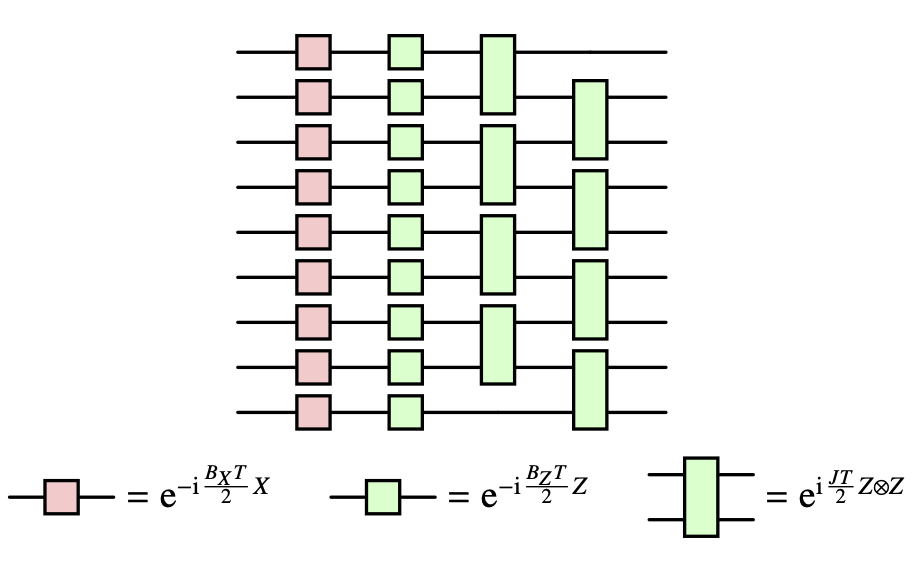

$H_1=-\sum_{n=1}^{N-1} Z_nZ_{n+1}+B_Z \sum_{n=1}^N Z_n$ (for open boundary conditions)

$H_2= B_X \sum_{n=1}^N X_n$

First-order Trotter decomposition: $U=e^{-{\rm i} \frac{T}{2}H_1}e^{-{\rm i} \frac{T}{2}H_2}$, with $dt=\frac{T}{2}$

Time evolution: $|\psi(t)\rangle=U^{M}|\psi(0)\rangle$, with $M=\frac{t}{dt}$


A practical simulation can be organized as follows.

* Define the quantum gates in each box.
* Build a one-step evolution gate from the boxes.
* Build the gates for an $n$-step evolution.
* Build the gate that prepares the initial state.
* Build the gates used for measurement.
* Combine and run these components.


In [ ]:
def X(qc,q,theta):
    """
    exp(-i*theta*X)
    """
    qc.rx(2*theta,q)
        
def Z(qc,q,theta):
    """
    exp(-i*theta*Z)
    """
    qc.rz(2*theta,q)
        
def ZZ(qc,q0,q1,theta):
    """
    exp(-i*theta*Z0*Z1)
    """
    qc.cx(q0,q1)
    qc.rz(2*theta,q1)
    qc.cx(q0,q1)

def CX(qc,q0,q1,theta):
    """
    c-exp(-i*theta*X1); q0 is the control qubit
    """
    qc.h(q1)
    qc.rz(theta,q1)
    qc.cx(q0,q1)
    qc.rz(-theta,q1)
    qc.cx(q0,q1)
    qc.h(q1)

def CZ(qc,q0,q1,theta):
    """
    c-exp(-i*theta*Z1); q0 is the control qubit
    """
    qc.rz(theta,q1)
    qc.cx(q0,q1)
    qc.rz(-theta,q1)
    qc.cx(q0,q1)

def CZZ(qc,q0,q1,q2,theta):
    """
    c-exp(-i*theta*Z1*Z2); q0 is the control qubit
    """
    qc.cx(q1,q2)
    CZ(qc,q0,q2,theta)
    qc.cx(q1,q2)

In [244]:
def U_ising(qc,q,h,m,dt):
    """
    exp(-i*dt*H_ising)
    h: coeff of transverse field
    m: coeff of longitudinal field
    """
    N = len(q)

    for i in range(N):
        X(qc,q[i],h*dt)

    for i in range(N):
        Z(qc,q[i],m*dt)

    for i in range(N-1):
        ZZ(qc,q[i],q[i+1],dt)
    ZZ(qc,q[N-1],q[0],dt)

def U_ising_dag(qc,q,h,m,dt):
    """
    exp(-i*dt*H_ising)
    h: coeff of transverse field
    m: coeff of longitudinal field
    """
    N = len(q)

    ZZ(qc,q[N-1],q[0],-dt)
    for i in reversed(range(N-1)):
        ZZ(qc,q[i],q[i+1],-dt)

    for i in range(N):
        Z(qc,q[i],-m*dt)

    for i in range(N):
        X(qc,q[i],-h*dt)

def cU_ising(qc,q,h,m,dt):
    """
    c-exp(-i*dt*H_ising)
    This is used to compute the vacuum persistence amplitude
    h: coeff of transverse field
    m: coeff of longitudinal field
    q[0] is the control qubit; N+1 qubits in total
    """
    Nq = len(q)

    for i in range(1,Nq):
        CX(qc,q[0],q[i],h*dt)

    for i in range(1,Nq):
        CZ(qc,q[0],q[i],m*dt)

    for i in range(1,Nq-1):
        CZZ(qc,q[0],q[i],q[i+1],dt)
    CZZ(qc,q[0],q[Nq-1],q[1],dt)

def swap(qc,q1,q2):
    N = len(q1)

    for i in range(N//2):
        qc.swap(q1[i],q2[i])

def cswap(qc,q0,q1,q2):
    N = len(q1)

    for i in range(N//2):
        qc.cswap(q0,q1[i],q2[i])

# Run the Simulation


In [258]:
class TFI:
    def __init__(self,N,h,m,T,dt):
        self.N = N
        self.h = h
        self.m = m
        self.dt= dt
        self.M = int(T/dt)

    def measurement(self):

        X    = np.zeros(self.M+1)
        Xerr = np.zeros(self.M+1)

        ZZ    = np.zeros(self.M+1)
        ZZerr = np.zeros(self.M+1)

        for i in range(self.M+1):

            backend = BasicSimulator()
            q = QuantumRegister(self.N,"q")
            qc = QuantumCircuit(q)
            
            op1= [('X' ,[self.N//4],1.0)]
            op1=SparsePauliOp.from_sparse_list(op1 , num_qubits=len(q))
            op2= [('ZZ',[0,self.N//2],1.0)]
            op2=SparsePauliOp.from_sparse_list(op2 , num_qubits=len(q))
            op=[op1,op2]

            for _ in range(i):
                U_ising(qc,q,self.h,self.m,self.dt)

            estimator= BackendEstimator(backend=backend)
            result = estimator.run([(qc,op)]).result()[0].data
            X[i],ZZ[i]=result.evs
            Xerr[i],ZZerr[i]=result.stds
        return X,Xerr,ZZ,ZZerr
    
    def vacuum(self,shots=1000):

        P    = np.zeros(self.M+1)

        for i in range(self.M+1):

            backend = BasicSimulator()
            q = QuantumRegister(self.N,"q")
            c = ClassicalRegister(self.N,'c')
            qc = QuantumCircuit(q,c)

            for _ in range(i):
                U_ising(qc,q,self.h,self.m,self.dt)

            qc.measure(q, c)
            sampler= BackendSampler(backend=backend)
            P[i] = sampler.run([(qc)],shots=shots).result()[0].data.c.get_counts()['0'*self.N]/shots 

        return P

    def renyi2(self,shots=100):

        S    = np.zeros(self.M+1)

        for i in range(self.M+1):

            backend = BasicSimulator()
            q1 = QuantumRegister(self.N,"q1")
            q2 = QuantumRegister(self.N,"q2")
            qc = QuantumCircuit(q1,q2)

            for _ in range(i):
                U_ising(qc,q1,self.h,self.m,self.dt)

            for _ in range(i):
                U_ising(qc,q2,self.h,self.m,self.dt)

            swap(qc,q1,q2) 

            for _ in range(i):
                U_ising_dag(qc,q1,self.h,self.m,self.dt)

            for _ in range(i):
                U_ising_dag(qc,q2,self.h,self.m,self.dt)

            qc.measure_all() 

            sampler= BackendSampler(backend=backend)
            S[i] = -0.5*np.log(sampler.run([(qc)],shots=shots).result()[0].data.meas.get_counts()['0'*2*self.N]/shots)

        return S

    def renyi2_destructive_circuit(self, step):
        """Two copies, Bell measurements on the left half, no ancilla."""
        q1 = QuantumRegister(self.N, "q1")
        q2 = QuantumRegister(self.N, "q2")
        c = ClassicalRegister(2 * (self.N // 2), "c")
        qc = QuantumCircuit(q1, q2, c)
        for _ in range(step):
            U_ising(qc, q1, self.h, self.m, self.dt)
            U_ising(qc, q2, self.h, self.m, self.dt)
        for site in range(self.N // 2):
            qc.cx(q1[site], q2[site])
            qc.h(q1[site])
            qc.measure(q1[site], c[2 * site])
            qc.measure(q2[site], c[2 * site + 1])
        return qc

    def renyi2_destructive(self, shots=4096, backend=None):
        """Estimate S2 in nats from the destructive SWAP measurement."""
        if backend is None:
            backend = AerSimulator()
        circuits = [self.renyi2_destructive_circuit(step) for step in range(self.M + 1)]
        results = BackendSampler(backend=backend).run(circuits, shots=shots).result()
        entropy = np.zeros(self.M + 1)
        error = np.zeros(self.M + 1)
        for step, result in enumerate(results):
            counts = result.data.c.get_counts()
            total = sum(counts.values())
            swap_sum = 0
            for bitstring, count in counts.items():
                bits = int(bitstring.replace(" ", ""), 2)
                antisymmetric_pairs = sum(
                    ((bits >> (2 * site)) & 1) * ((bits >> (2 * site + 1)) & 1)
                    for site in range(self.N // 2)
                )
                swap_sum += (-1) ** antisymmetric_pairs * count
            purity = swap_sum / total
            if purity <= 0:
                raise ValueError("Estimated purity is non-positive; increase shots")
            entropy[step] = -np.log(purity)
            error[step] = np.sqrt(max(0.0, 1 - purity**2) / total) / purity
        return entropy, error

    def vacuum_hadamard_re(self):

        P    = np.zeros(self.M+1)
        Perr = np.zeros(self.M+1)

        for i in range(self.M+1):

            backend = BasicSimulator()
            q = QuantumRegister(self.N+1,"q")
            qc = QuantumCircuit(q)
            qc.h(q[0])

            for _ in range(i):
                cU_ising(qc,q,self.h,self.m,self.dt)

            op= [('X' ,[0],1.0)]
            op=SparsePauliOp.from_sparse_list(op , num_qubits=len(q))

            estimator= BackendEstimator(backend=backend)
            result = estimator.run([(qc,op)]).result()[0].data
            P[i]=result.evs
            Perr[i]=result.stds

        return P,Perr

    def vacuum_hadamard_im(self):

        P    = np.zeros(self.M+1)
        Perr = np.zeros(self.M+1)

        for i in range(self.M+1):

            backend = BasicSimulator()
            q = QuantumRegister(self.N+1,"q")
            qc = QuantumCircuit(q)
            qc.h(q[0])
            qc.sdg(q[0])

            for _ in range(i):
                cU_ising(qc,q,self.h,self.m,self.dt)

            op= [('X' ,[0],1.0)]
            op=SparsePauliOp.from_sparse_list(op , num_qubits=len(q))

            estimator= BackendEstimator(backend=backend)
            result = estimator.run([(qc,op)]).result()[0].data
            P[i]=result.evs
            Perr[i]=result.stds

        return P,Perr

    def renyi2_hadamard(self):

        S    = np.zeros(self.M+1)
        Serr = np.zeros(self.M+1)

        for i in range(self.M+1):

            backend = BasicSimulator()
            q0 = QuantumRegister(1,"q0")
            q1 = QuantumRegister(self.N,"q1")
            q2 = QuantumRegister(self.N,"q2")
            qc = QuantumCircuit(q0,q1,q2)

            qc.h(q0)

            for _ in range(i):
                U_ising(qc,q1,self.h,self.m,self.dt)

            for _ in range(i):
                U_ising(qc,q2,self.h,self.m,self.dt)

            cswap(qc,q0,q1,q2) 

            op= [('X' ,[0],1.0)]
            op=SparsePauliOp.from_sparse_list(op , num_qubits=1+2*len(q1))

            estimator= BackendEstimator(backend=backend)
            result = estimator.run([(qc,op)]).result()[0].data
            S[i]=-np.log(result.evs)
            Serr[i]=result.stds/result.evs

        return S, Serr
    

In [226]:
N=10
hx=1.05
hz=0.5
T=2.5
dt=0.05

In [227]:
q=TFI(N,hx,hz,T,dt)

In [228]:
x,xerr,z,zerr=q.measurement()

In [230]:
p=q.vacuum()
p2r,p2rerr=q.vacuum_hadamard_re()
p2i,p2ierr=q.vacuum_hadamard_im()

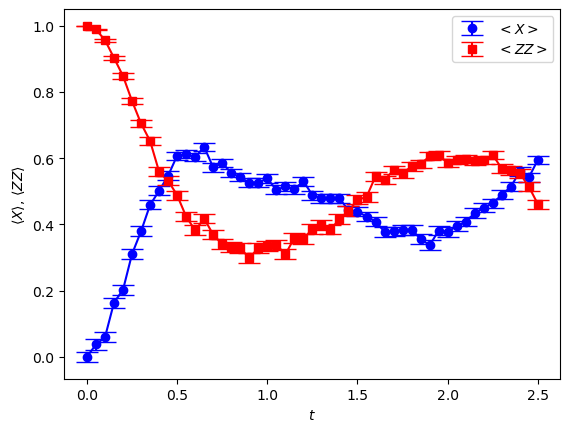

In [231]:
times= dt*np.arange(int(T/dt)+1)
plt.errorbar(times,x,yerr=xerr, fmt='o', capsize=8, color='blue',label=r"$<X>$")
plt.plot(times,x, 'b-')
plt.errorbar(times,z,yerr=zerr, fmt='s', capsize=8, color='red',label=r"$<ZZ>$")
plt.plot(times,z, 'r-')

plt.xlabel("$t$")
plt.ylabel(r"$\langle X\rangle$, $\langle ZZ\rangle$")
plt.legend()
plt.show()

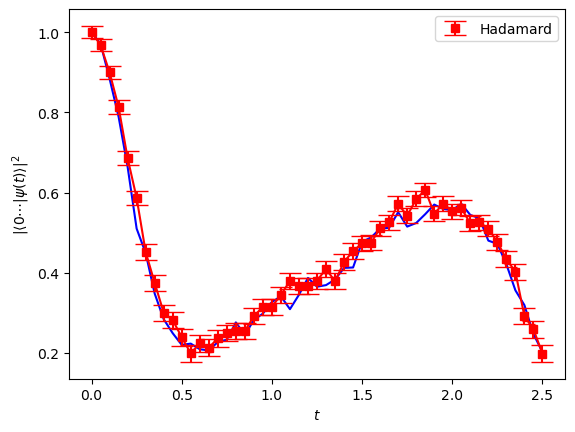

In [234]:
times= dt*np.arange(int(T/dt)+1)
plt.plot(times,p, 'b-')

p2=p2r**2+p2i**2
p2err=np.sqrt(p2rerr**2+p2ierr**2)

plt.errorbar(times,p2,yerr=p2err, fmt='s', capsize=8, color='red',label=r"Hadamard")
plt.plot(times,p2, 'r-')

plt.xlabel("$t$")
plt.ylabel(r"$\left|\langle 0\cdots|\psi(t)\rangle\right|^2$")

plt.legend()
plt.show()

## Second Rényi Entropy with a Destructive SWAP Test

Measure the same left half, $A=\{0,\ldots,N/2-1\}$, used by the existing `renyi2` and `renyi2_hadamard` calculations. Prepare two copies of the state at each time, and apply a CNOT, a Hadamard gate, and $Z$ measurements to each pair $q_{1,j},q_{2,j}$. Assign $-1$ to a pair with outcome $11$ and $+1$ to every other outcome. The shot average of the product of all pair signs gives $\mathrm{Tr}(\rho_A^2)$. Outcome $11$ is the antisymmetric Bell state, not a failed Bell measurement, so no shots are discarded. To match the existing figure, display $S_2=-\ln\mathrm{Tr}(\rho_A^2)$ using the natural logarithm. The measurement circuit uses only ordinary gates and measurements, with neither ancilla qubits nor `cswap`.


In [259]:
N=6
hx=1.05
hz=0.5
T=2.5
dt=0.05
q=TFI(N,hx,hz,T,dt)

In [260]:
destructive_shots = 4096
s=q.renyi2()
s2,s2err=q.renyi2_hadamard()
s3,s3err=q.renyi2_destructive(shots=destructive_shots)

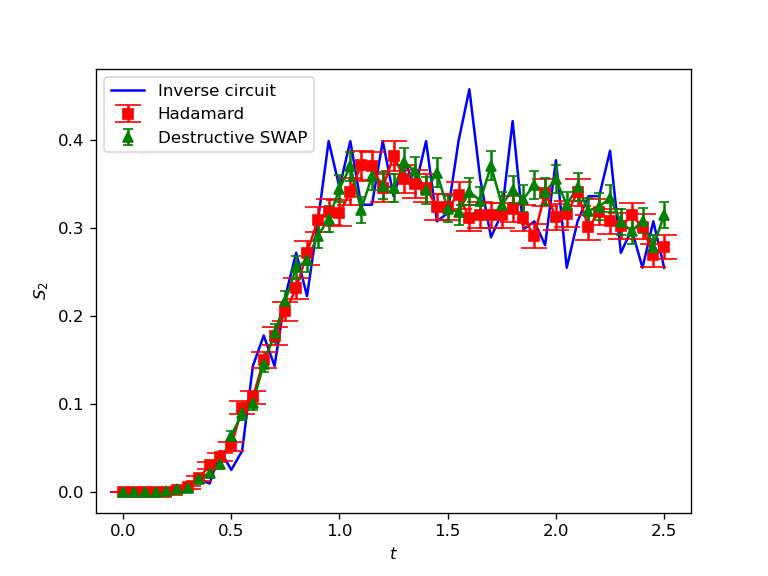

In [261]:
times= dt*np.arange(int(T/dt)+1)
plt.plot(times,s, 'b-',label='Inverse circuit')

plt.errorbar(times,s2,yerr=s2err, fmt='s', capsize=8, color='red',label=r"Hadamard")
plt.plot(times,s2, 'r-')
plt.errorbar(times,s3,yerr=s3err, fmt='^', capsize=3, color='green',
             label=r"Destructive SWAP")
plt.plot(times,s3, 'g-')

plt.xlabel("$t$")
plt.ylabel(r"$S_2$")

plt.legend()
plt.show()

### **Exercise**

Vary the parameters of the TFI model and study its thermalization.


### **Exercise**

Change the initial state of the TFI model—for example, use an $X$ eigenstate, an antiferromagnetic ground state, or a state containing a domain wall—and study its thermalization.


### **Exercise**

For the PXP model $H=-\sum_{i=1}^{N}P_{i-1}X_i P_{i+1}$, study thermalization using $|\psi(0)\rangle=|\uparrow\cdots\uparrow\rangle$ and $|\psi(0)\rangle=|\uparrow\downarrow\cdots\uparrow\downarrow\rangle$ as initial conditions.

Here $P_i=|\uparrow_i\rangle\langle\uparrow_i|$ projects qubit $i$ onto the $\uparrow$ state.


Use the gates below for the additional operations required by the PXP model.


In [ ]:
def ZX(qc,q0,q1,theta):
    """
    exp(-i*theta*Z0*X1)
    """
    qc.h(q1)
    qc.cx(q0,q1)
    qc.rz(2*theta,q1)
    qc.cx(q0,q1)
    qc.h(q1)

def CZX(qc,q0,q1,q2,theta):
    """
    c-exp(-i*theta*Z1*X2); q0 is the control qubit
    """
    qc.h(q2)
    qc.ccx(q0,q1,q2)
    CZ(qc,q0,q2,theta)
    qc.ccx(q0,q1,q2)
    qc.h(q2)

def ZZX(qc,q0,q1,q2,theta):
    """
    exp(-i*theta*Z0*Z1*X2)
    """
    qc.h(q2)
    qc.cx(q0,q2)
    qc.cx(q1,q2)
    qc.rz(2*theta,q2)
    qc.cx(q1,q2)
    qc.cx(q0,q2)
    qc.h(q2)

def CZZX(qc,q0,q1,q2,q3,theta):
    """
    c-exp(-i*theta*Z1*Z2*X3); q0 is the control qubit
    """
    qc.h(q3)
    qc.ccx(q0,q1,q3)
    qc.ccx(q0,q2,q3)
    qc.rz(2*theta,q3)
    qc.ccx(q0,q2,q3)
    qc.ccx(q0,q1,q3)
    qc.h(q3)


### **Exercise**

Analyze with quantum computation the Hamiltonian previously studied with classical computation.


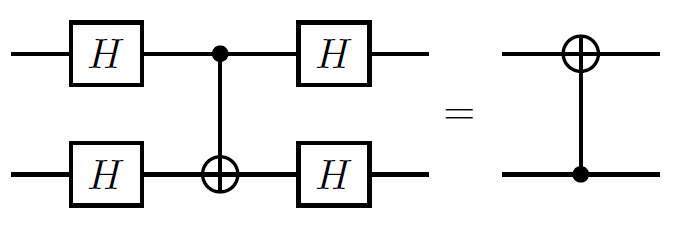

### Constructing Other Gates


Construct $R_{XX}$ and $R_{YY}$ from $R_{ZZ}$.


In [ ]:
def ZZ(qc,q0,q1,theta):
    """
    exp(-i*theta*Z0*Z1)
    """
    qc.cx(q0,q1)
    qc.rz(2*theta,q1)
    qc.cx(q0,q1)

def XX(qc,q0,q1,theta):
    """
    exp(-i*theta*X0*X1)
    """
    qc.cx(q0,q1)
    qc.rx(2*theta,q0)
    qc.cx(q0,q1)

def YY(qc,q0,q1,theta):
    """
    exp(-i*theta*Y0*Y1)
    """
    qc.sdg(q0); qc.sdg(q1)
    qc.cx(q0,q1)
    qc.rx(2*theta,q0)
    qc.cx(q0,q1)
    qc.s(q0); qc.s(q1)

Likewise, one can construct $e^{-{\rm i}\theta Z\cdots Z}$ and then change basis to obtain $e^{-{\rm i}\theta X\cdots X}$ and analogous operators.
